# Gaia BH3: a Gaia DR4 EAS astrometry only fit

Fit source **4318465066420528000** from the local EAS prerelease XML.
The luminous star is body 0 and the dark black hole companion is body 1.
Both masses are in **solar masses**.

Data credit: **ESA/Gaia/DPAC**. See the
[data provenance](../../orbitize/example_data/gaia_dr4_eas_README.md),
[ESA's DR4 BH3 example](https://github.com/esa/gaia-bhthree/tree/gaia-dr4-prerelease),
and [Panuzzo et al. (2024)](https://arxiv.org/abs/2404.10486). If you use these datasets for any publication, please cite these works.

In [1]:
from copy import copy
from pathlib import Path
from time import perf_counter
from astropy import units as u
import matplotlib.pyplot as plt
import numpy as np
import orbitize
from orbitize import gaia, priors, read_input, sampler, system, plot

np.random.seed(42)
rng = np.random.default_rng(42)
plt.style.use("default")

source_id = 4318465066420528000
ref_epoch_mjd = 57936.375  # J2017.5, MJD(TCB)
stellar_mass = 0.76  # Msun; Panuzzo et al. (2024), Table 3
stellar_mass_err = 0.05  # Msun

## 1. Read and combine the CCD measurements

Keep the AGIS-used CCDs and combine them once per transit using the existing
bootstrap helper. These uncertainties stay fixed during MCMC. A separate sampled jitter is added in quadrature.


In [2]:
# pull data
xml_path = Path(orbitize.DATADIR) / "GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml"
ccd_data = read_input.from_dl2(xml_path, source_id)

# combine transits
data = read_input.combine_transits(ccd_data, rng=rng)

print(f"{len(ccd_data)} CCD measurements → {len(data)} transits")
data[:5]

558 CCD measurements → 63 transits


source_id,transit_id,obs_time_tcb,centroid_pos_al,centroid_pos_error_al,parallax_factor_al,scan_pos_angle,field_of_view,n_ccd
,,d,mas,mas,,rad,,
int64,int64,float64,float64,float64,float32,float64,int64,int64
4318465066420528000,20114916805338633,56957.61152002953,147.1957396992727,0.029565029151369094,0.70821655,-1.030554645838993,1,9
4318465066420528000,20119009095238725,56957.68550881944,146.81171045250608,0.03905695584489787,0.70841557,-1.0316683244136728,2,8
4318465066420528000,22150086612000799,56994.41374902246,380.317258080725,0.05322999365631929,-0.46652928,-0.08924270814409281,2,7
4318465066420528000,22159827441309232,56994.58993762592,379.0228104713417,0.06780589705281188,-0.45942295,-0.10090981680327325,1,9
4318465066420528000,22163919699111981,56994.663954163225,378.45405260795496,0.036298120179572624,-0.4564245,-0.10582271812036592,2,9


## 2. System and priors

Let's use the **Period** basis. Period is log-uniform over 1–50 years, black hole mass log-uniform over
1–100 Msun, eccentricity uniform over 0–0.95, inclination isotropic,
and both angles and periastron phase uniform.

The luminous star mass has a positive Gaussian prior, 0.76 +/- 0.05 Msun
([Table 3](https://arxiv.org/html/2404.10486v2#S2.T3)). That stellar estimate
used a Gaia-based distance. **Parallax is fitted with a uniform 0.1–5 mas
prior**. Jitter is log-uniform over 0.0001–100 mas. The four linear terms retain the
current basis defaults: +/-10,000 mas for offsets and +/-10,000 mas/yr for PM.


In [3]:
dr4 = gaia.DR4LogProb(
    source_id,
    data,
    ref_epoch_mjd=ref_epoch_mjd,
    jitter_prior=priors.LogUniformPrior(1e-4, 100),
)

# plx is placeholder until we define priors
my_sys = system.System(
    1,
    None,
    stellar_mass,
    plx=2.0,
    mass_err=stellar_mass_err,
    fit_secondary_mass=True,
    gaia=dr4,
    tau_ref_epoch=ref_epoch_mjd,
    fitting_basis="Period",
)
idx = my_sys.param_idx

# defining priors
for name, prior in {
    "per1": priors.LogUniformPrior(1.0, 50.0),
    "ecc1": priors.UniformPrior(0.0, 0.95),
    "m1": priors.LogUniformPrior(1.0, 100.0),
    "plx": priors.UniformPrior(0.1, 5.0),
}.items():
    my_sys.sys_priors[idx[name]] = prior

## 3. Starting the sampler

The Gaia model includes five astrometric parameters: two position offsets, two proper motion components, and parallax. For each walker, we draw parallax and the orbital parameters from their priors, then use the Gaia measurements to initialize the four position and proper motion terms.

In [4]:
num_walkers = 128
burn_steps = 100
num_steps = 500
thin = 1

# start sampler and draw initial walkers
mcmc = sampler.MCMC(
    my_sys, num_temps=10, num_walkers=num_walkers, num_threads=10
)
positions = mcmc.curr_pos.reshape(-1, mcmc.num_params)
full_positions = mcmc._fill_in_fixed_params(positions)
ra, dec, _, _ = my_sys.compute_all_orbits(
    full_positions.T, epochs=dr4.epochs_mjd, params_basis="fitting"
)

linear_columns = [
    mcmc.sampled_param_idx[name] for name in ("alpha0", "delta0", "pm_ra", "pm_dec")
]
# guess initial four position and proper motion terms
for walker, params in enumerate(full_positions):
    positions[walker, linear_columns] = dr4.guess_initial_astrometry(
        ra[:, 0, walker],
        dec[:, 0, walker],
        params[idx["plx"]],
        params[idx["dr4_jitter"]],
    )

mcmc.check_prior_support()

## 4. Run once, then inspect

The next cell starts the fit.
These settings are a computational budget to inspect orientation, period, mass and jitter.


In [5]:
start = perf_counter()
run = mcmc.run_sampler(num_walkers * num_steps, burn_steps=burn_steps, thin=thin)
post = mcmc.results.post
print(f"Run took {(perf_counter() - start) / 60:.1f} minutes")
print("Mean acceptance per temperature:", np.mean(run.acceptance_fraction, axis=1))
print("Temperature-swap acceptance:", run.tswap_acceptance_fraction)
print(f"Best log-likelihood: {np.nanmax(mcmc.results.lnlike):.3f}")

Starting Burn in


/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: Runt

100/100 steps of burn-in complete
Burn in complete. Sampling posterior now.
500/500 steps completed
Run complete
Run took 1.0 minutes
Mean acceptance per temperature: [0.12335937 0.081625   0.09271875 0.10385938 0.11267188 0.11975
 0.12270312 0.12303125 0.11498438 0.06892188]
Temperature-swap acceptance: [0.00654687 0.10582812 0.26075781 0.34074219 0.41809375 0.54121094
 0.63960938 0.54707031 0.21353125 0.00082812]
Best log-likelihood: -65.645


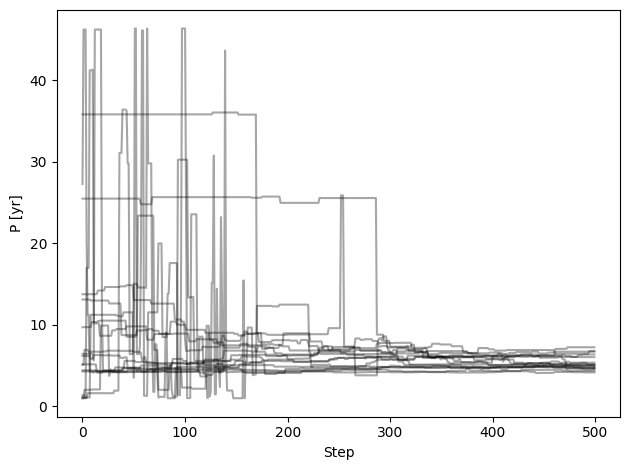

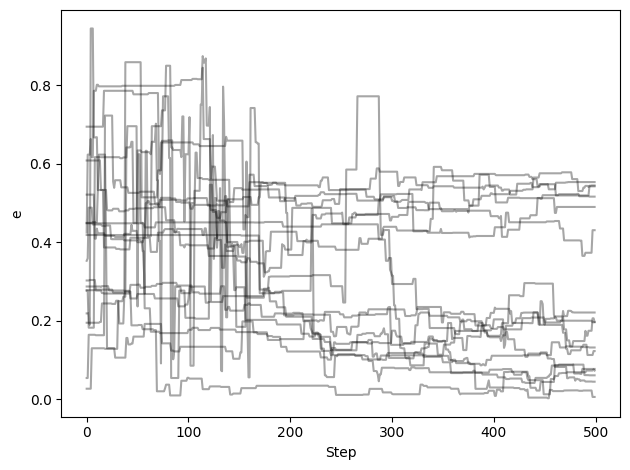

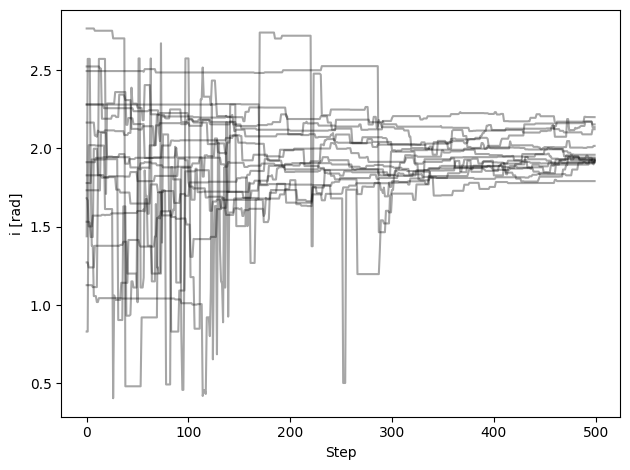

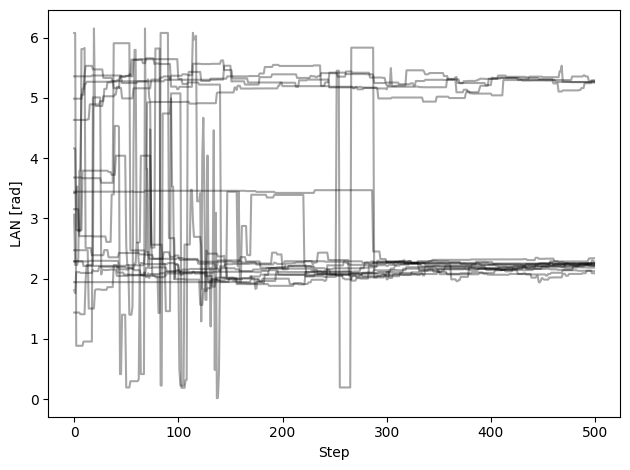

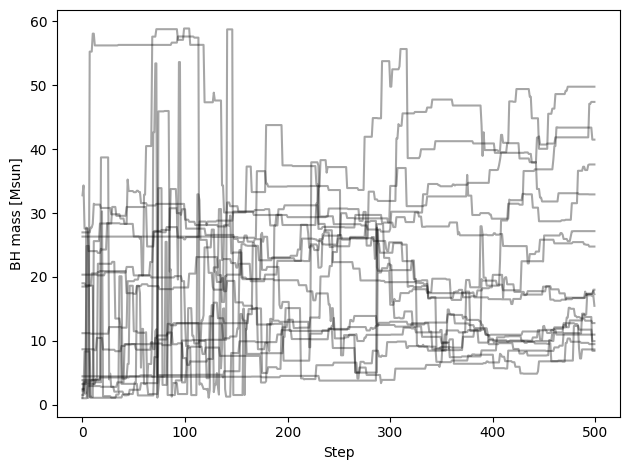

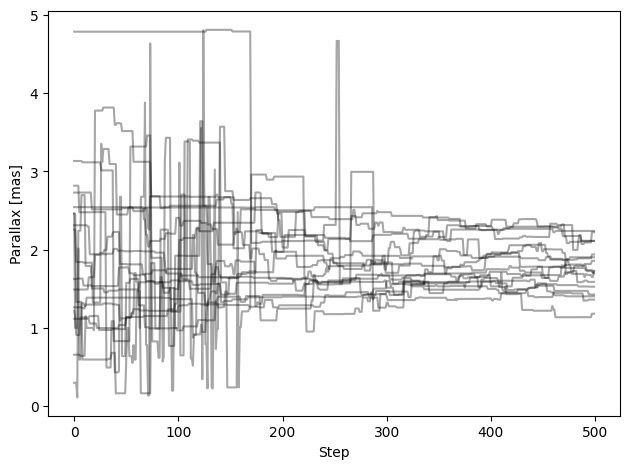

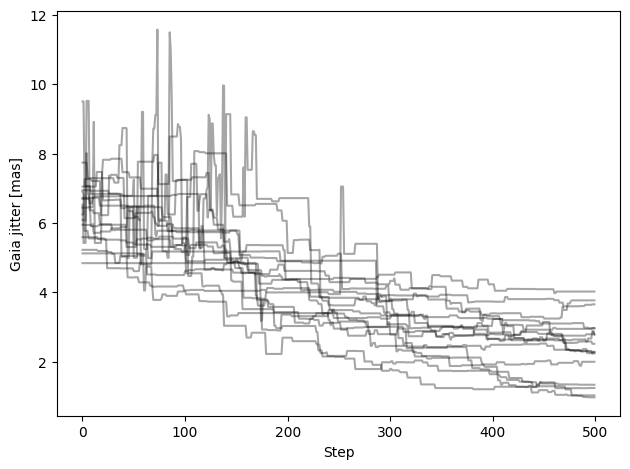

In [6]:
# checking chain convergence

chain_params = ["per1", "ecc1", "inc1", "pan1", "m1", "plx", "dr4_jitter"]
chain_labels = [
    "P [yr]",
    "e",
    "i [rad]",
    "LAN [rad]",
    "BH mass [Msun]",
    "Parallax [mas]",
    "Gaia jitter [mas]",
]
chain_figures = mcmc.examine_chains(
    param_list=chain_params,
    n_walkers=16,
    transparency=0.35,
)
for fig, label in zip(chain_figures, chain_labels):
    fig.axes[0].set_ylabel(label)
    fig.tight_layout()

## 5. Corner Plot

Let's take a look at the corner plot for BH3. Orange lines show true parameters from the best fit in the paper.

Text(0.5, 0.98, 'Orange markers show Panuzzo et al. (2024)')

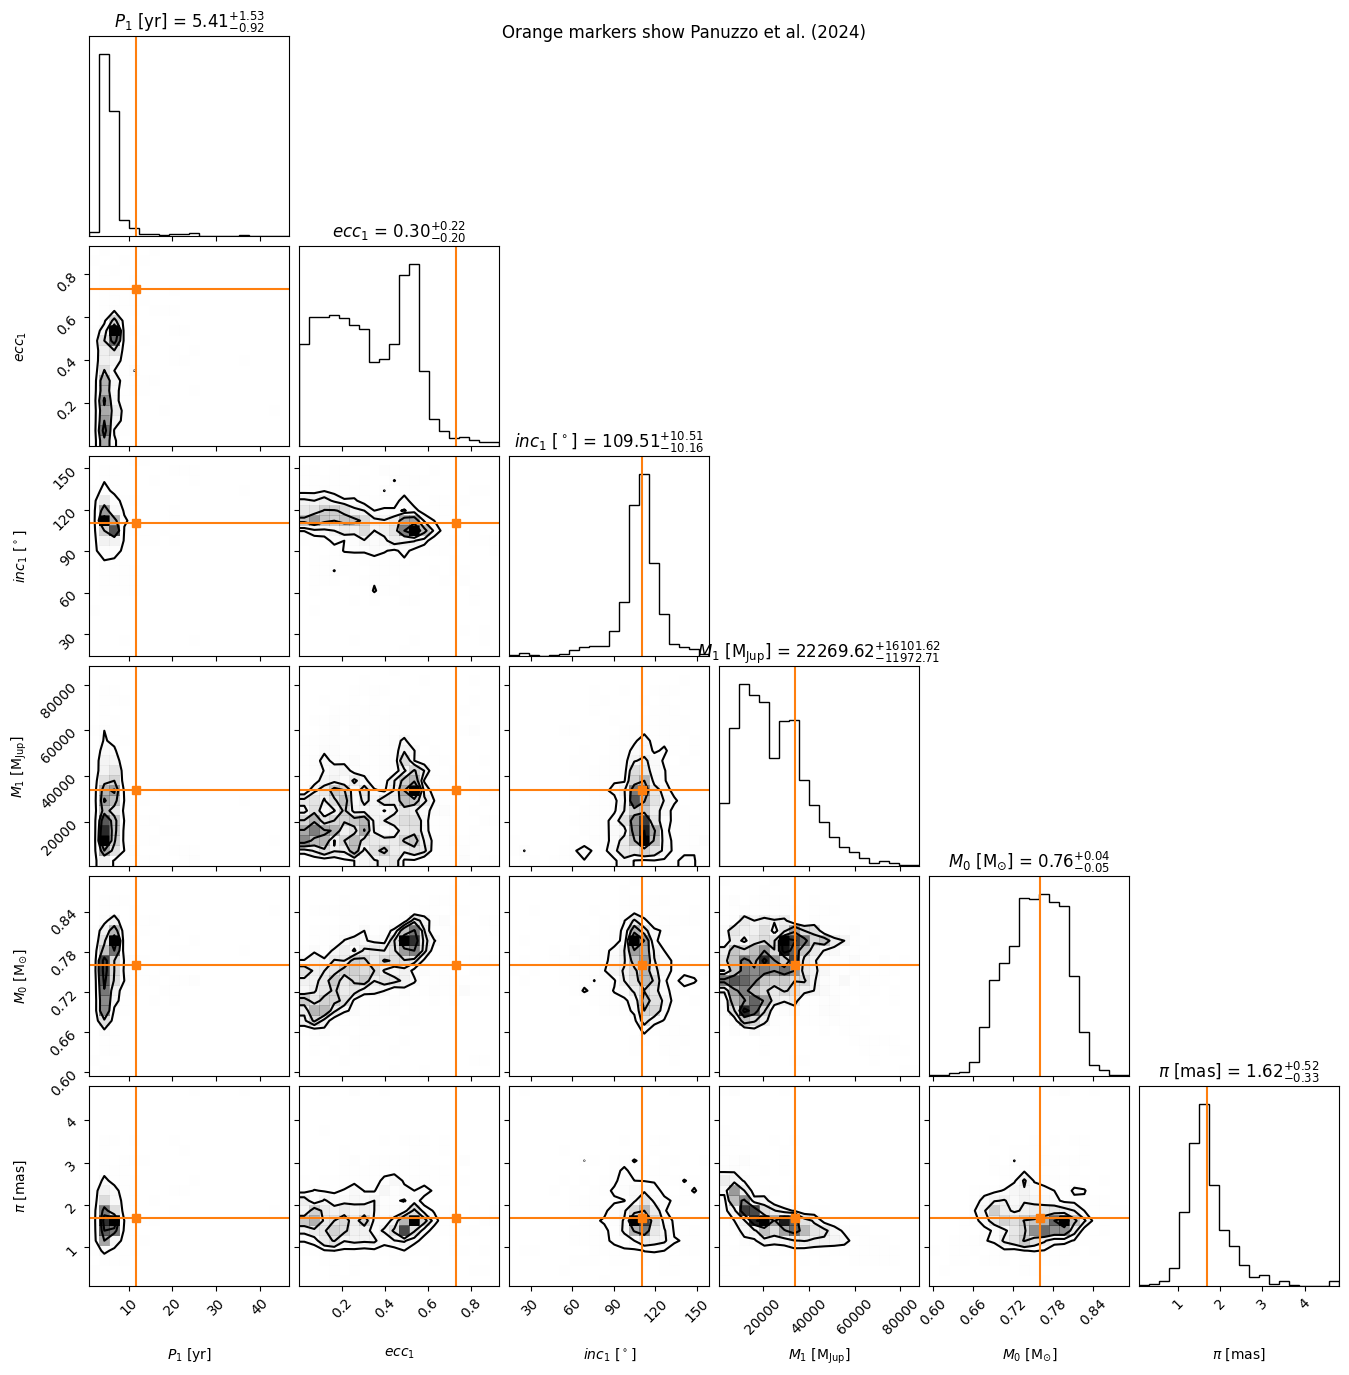

In [7]:

published_fit = [
    4253.1 / 365.25, 0.7291, 110.580,
    32.70 * u.Msun.to(u.Mjup), 0.76, 1.6933,
]

corner_figure = plot.plot_corner(
    mcmc.results,
    param_list=["per1", "ecc1", "inc1", "m1", "m0", "plx"],
    plot_priors=False,
    downsample=min(20_000, len(post)),
    truths=published_fit,
    truth_color="tab:orange",
    show_titles=True,
    plot_datapoints=False,
)
corner_figure.suptitle("Orange markers show Panuzzo et al. (2024)")

## 5. On-sky orbit

Let's take a look at best fit Keplerian orbit on sky.

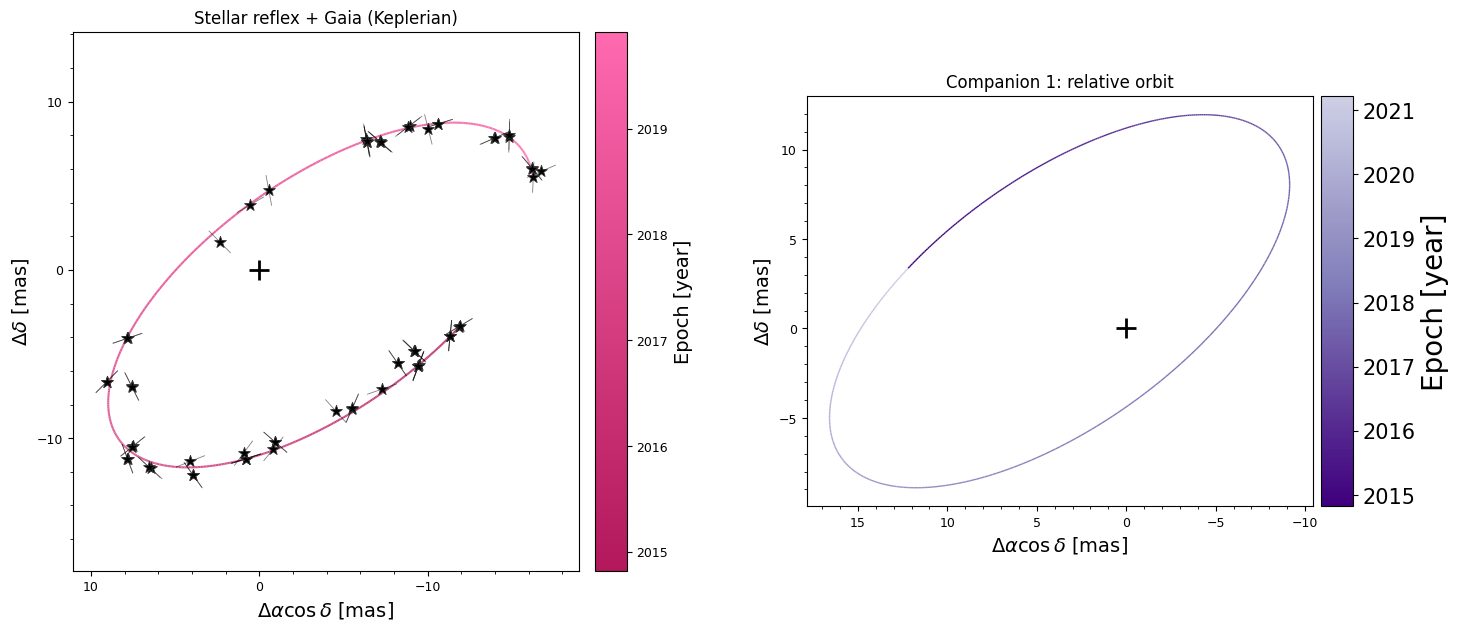

In [9]:
best_idx = np.nanargmax(mcmc.results.lnlike)
best_results = copy(mcmc.results)
best_results.post = mcmc.results.post[[best_idx]]
best_results.lnlike = mcmc.results.lnlike[[best_idx]]

orbit_figure = best_results.plot_dr4_orbit(
    my_sys, include_planet=True, include_jitter=True, fontsize=14
)
plt.show()

## 6. Save the run

This writes the posterior, likelihoods, system and Gaia observations to HDF5
in the current notebook directory. Use a new filename for each comparison run.

In [10]:
mcmc.results.save_results("Gaia_DR4_BH3_results.hdf5")